In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


# Data Domain Understanding
Satu baris data adalah satu laporan atau satu observasi tentang dugaan penyalahgunaan domain pada waktu tertentu.

# Deep Exploratory Data Analysis (EDA)

In [3]:
DRIVE_TRAINING_FILE_PATH = '/content/drive/MyDrive/TeamLearningByDoing/data/raw/training.csv'
DRIVE_PREDICT_FILE_PATH = '/content/drive/MyDrive/TeamLearningByDoing/data/raw/predict.csv'

# Load the CSV file into a pandas DataFrame
try:
    df = pd.read_csv(DRIVE_TRAINING_FILE_PATH)
    print(f"Successfully loaded '{DRIVE_TRAINING_FILE_PATH}' into a DataFrame.")
except FileNotFoundError:
    print(f"Error: The file '{DRIVE_TRAINING_FILE_PATH}' was not found. Please check the path and try again.")
    df = None # Set df to None in case of error
except Exception as e:
    print(f"An error occurred while loading the file: {e}")
    df = None

Successfully loaded '/content/drive/MyDrive/TeamLearningByDoing/data/raw/training.csv' into a DataFrame.


### Basic Data Exploration

In [4]:
if df is not None:
    print("\nFirst 5 rows of the DataFrame:")
    display(df.head())

    print("\nDataFrame Information:")
    df.info()

    print("\nDescriptive Statistics:")
    display(df.describe())


First 5 rows of the DataFrame:


,url,brand,discovered,confidence_level,ip,domain,sld,category,registrar,registration_date
0,https://lucah3.***********.my.id/,Telegram,5/1/2024 21:52,100,NaN,***********.my.id,my.id,phishingg,PT Web Media Technology Indonesia,5/14/2026
1,https://dpmptsp.*********.go.id/petapotensi/da...,judi online,8/5/2024 20:41,100,103.162.68.84,*********.go.id,go.id,online gambling,Kementerian Komunikasi dan Informatika,5/11/2009
2,http://klikpad.bkpd.**************.go.id/klikp...,-,6/14/2024 7:05,100,103.18.117.8,**************.go.id,go.id,online gambling,Kementerian Komunikasi dan Informatika,3/13/2008
3,https://sisumakerpublik.********************.g...,-,8/4/2024 6:20,100,103.113.3.225,********************.go.id,go.id,online gambling,Kementerian Komunikasi dan Informatika,7/28/2009
4,https://bappeda.**********.go.id/e-koor/storag...,-,8/4/2024 16:10,100,103.170.105.197,**********.go.id,go.id,online gambling,Kementerian Komunikasi dan Informatika,1/13/2012



DataFrame Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8400 entries, 0 to 8399
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   url                8400 non-null   object
 1   brand              7501 non-null   object
 2   discovered         8400 non-null   object
 3   confidence_level   8400 non-null   int64 
 4   ip                 7143 non-null   object
 5   domain             8400 non-null   object
 6   sld                8400 non-null   object
 7   category           8400 non-null   object
 8   registrar          8386 non-null   object
 9   registration_date  8379 non-null   object
dtypes: int64(1), object(9)
memory usage: 656.4+ KB

Descriptive Statistics:


,confidence_level
count,8400.000000
mean,102.403571
std,49.928836
min,-20.000000
25%,100.000000
50%,100.000000
75%,100.000000
max,1000.000000


### Analyzing and Cleaning The Target

            category  Count
0    online gambling   5357
1           phishing   2236
2              other    272
3               spam    184
4            malware    177
5    Online Gambling     52
6              Brand     43
7   online gamblingg     38
8          phishingg     17
9              Other     10
10          FakeShop      5
11             brand      2
12            otherr      2
13          malwaree      2
14             spamm      1
15          violence      1
16       PIIExposure      1


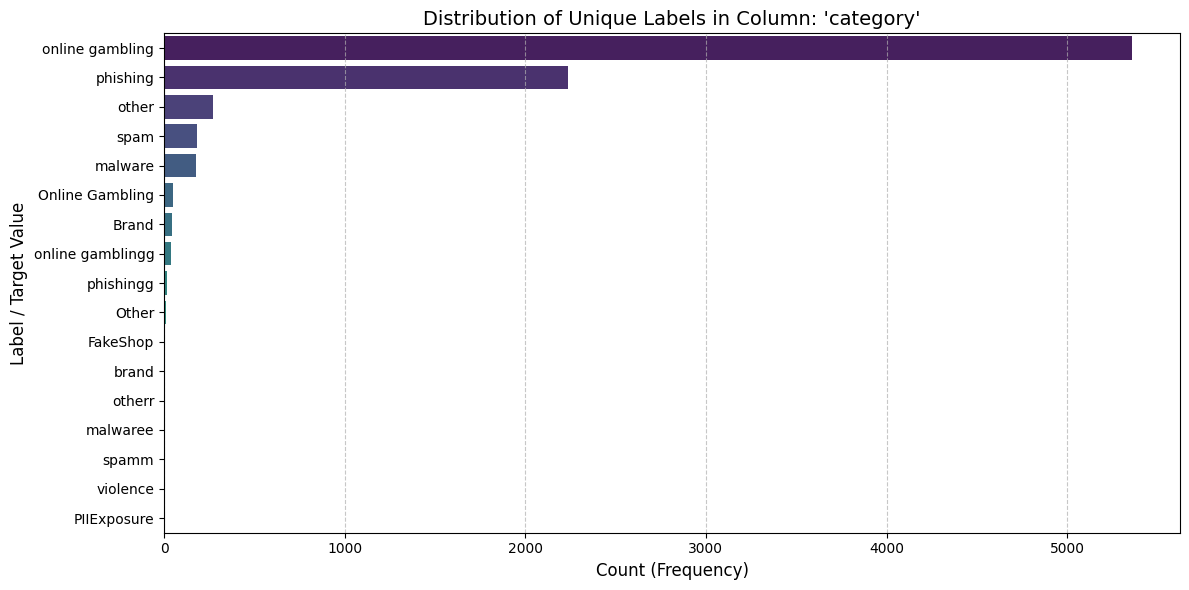

Labels list: ['phishingg', 'online gambling', 'spam', 'phishing', 'other', 'malware', 'online gamblingg', 'Online Gambling', 'Brand', 'Other', 'FakeShop', 'spamm', 'brand', 'violence', 'otherr', 'PIIExposure', 'malwaree']


In [5]:
# CATEGORICAL / LABELS ONLY
COLUMN_TARGET_LABELS = "category"

class UniqueLabelAnalyzer:
    def __init__(self, dataset, column_name):
        self.dataset = dataset
        self.column_name = column_name

        is_df_available = dataset is None
        is_column_exist = column_name not in dataset.columns

        if is_df_available or is_column_exist:
            self.labels = []
            self.value_counts = None
        else:
            # Get unique values as a list (including nulls if any)
            self.labels = list(dataset[column_name].unique())

            # Prepare value counts for visualization
            value_counts = dataset[column_name].value_counts(dropna=False).reset_index()
            value_counts.columns = [column_name, 'Count']
            self.value_counts = value_counts

    @property
    def distribution(self):
        if self.value_counts is None:
            print("No dataset or column loaded to visualize.")
            return

        print(self.value_counts)

        # Create a horizontal bar plot for better readability
        plt.figure(figsize=(12, 6))
        sns.barplot(
            x='Count',
            y=self.column_name,
            data=self.value_counts,
            palette='viridis',
            hue=self.column_name,
            legend=False
        )
        plt.title(f"Distribution of Unique Labels in Column: '{self.column_name}'", fontsize=14)
        plt.xlabel("Count (Frequency)", fontsize=12)
        plt.ylabel("Label / Target Value", fontsize=12)
        plt.grid(axis='x', linestyle='--', alpha=0.7)
        plt.tight_layout()
        plt.show()

def get_unique_labels(dataset, column_name):
    return UniqueLabelAnalyzer(dataset, column_name)

is_df_available = df is not None
if is_df_available:
    arr_category_labels = get_unique_labels(df, COLUMN_TARGET_LABELS)
    arr_category_labels.distribution
    print("Labels list:", arr_category_labels.labels)

  cleaned_category  Count
0  online gambling   5447
1         phishing   2253
2            other    284
3             spam    185
4          malware    179
5            brand     45
6         fakeshop      5
7         violence      1
8      piiexposure      1


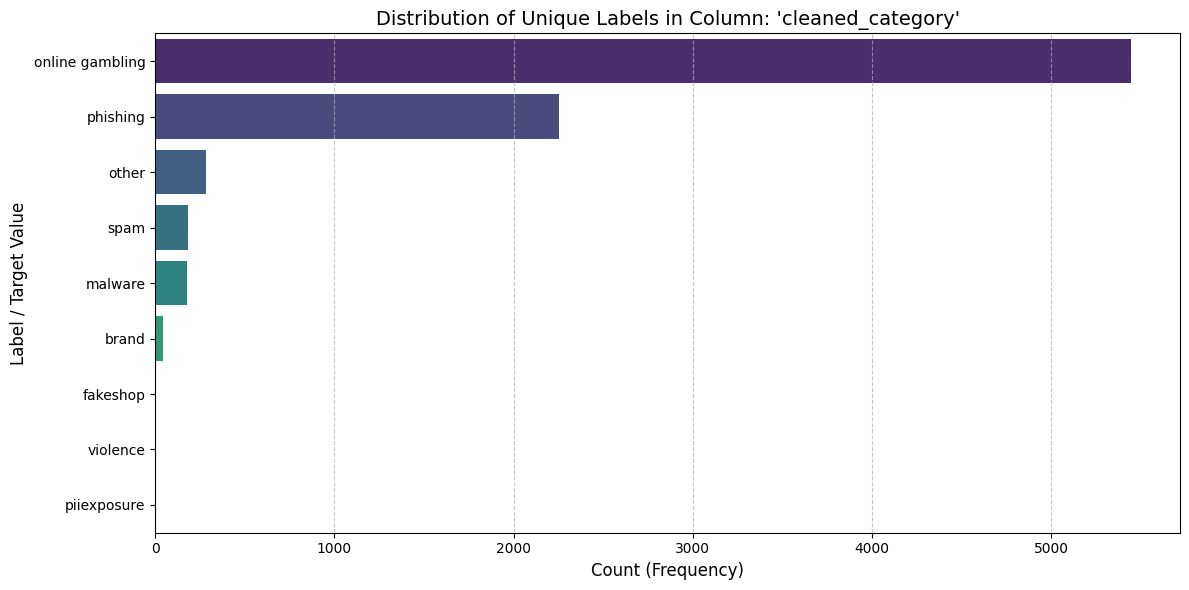

Labels list: ['phishing', 'online gambling', 'spam', 'other', 'malware', 'brand', 'fakeshop', 'violence', 'piiexposure']

[WARNING] unmapped labels: ['online gambling' 'piiexposure']


In [6]:
STATIC_LABELS_GROUND_TRUTHS = [
    'online_gambling', 'phishing', 'spam', 'malware',
    'brand', 'fakeshop', 'violence', 'pii_exposure', 'other'
]

LABEL_MAPPING = {
    # Online Gambling
    'online gambling': 'online gambling',
    'Online Gambling': 'online gambling',
    'online gamblingg': 'online gambling',

    # Phishing
    'phishing': 'phishing',
    'phishingg': 'phishing',

    # Malware
    'malware': 'malware',
    'malwaree': 'malware',

    # Spam
    'spam': 'spam',
    'spamm': 'spam',

    # FakeShop
    'FakeShop': 'fakeshop',

    # Brand
    'brand': 'brand',
    'Brand': 'brand',

    # Violence
    'violence': 'violence',

    # PII Exposure
    'PIIExposure': 'piiexposure',

    # Other
    'other': 'other',
    'Other': 'other',
    'otherr': 'other'
}

if df is not None:
    df['cleaned_category'] = df['category'].map(LABEL_MAPPING).fillna(df['category'])

    get_cleaned_category = get_unique_labels(df, 'cleaned_category')
    get_cleaned_category.distribution

    print("Labels list:", get_cleaned_category.labels)

    unmapped_labels = df[~df['cleaned_category'].isin(STATIC_LABELS_GROUND_TRUTHS)]['cleaned_category'].unique()
    is_unmapped_lables_exist = len(unmapped_labels) > 0
    if is_unmapped_lables_exist:
        print(f"\n[WARNING] unmapped labels: {unmapped_labels}")
    else:
        print("\n[SUCCESS] All labels has been mapped into Ground Truth.")
else:
    print("DataFrame 'df' is None. Cannot perform label mapping and analysis.")


### Analyzing Missing Data

brand missing val:
'NaN/Null' = 899
'undefined' = 0
'0' = 0
'' '' = 0
'-' = 4113


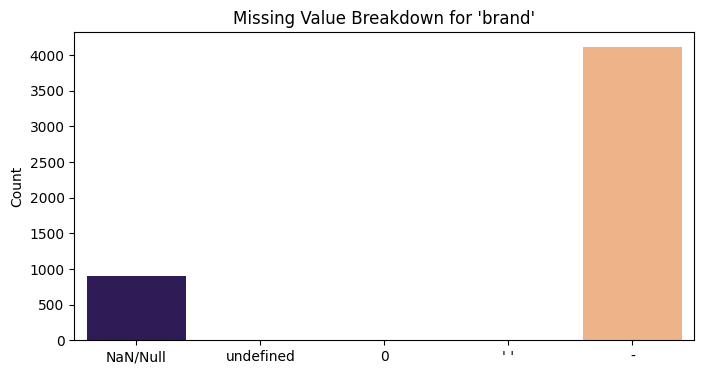

ip missing val:
'NaN/Null' = 1257
'undefined' = 0
'0' = 0
'' '' = 0
'-' = 0


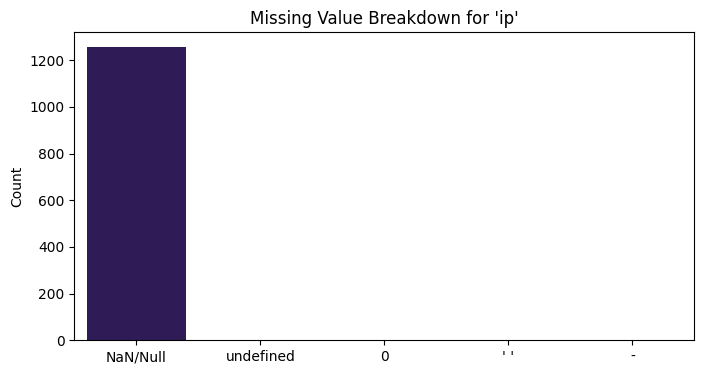

registrar missing val:
'NaN/Null' = 14
'undefined' = 0
'0' = 0
'' '' = 0
'-' = 0


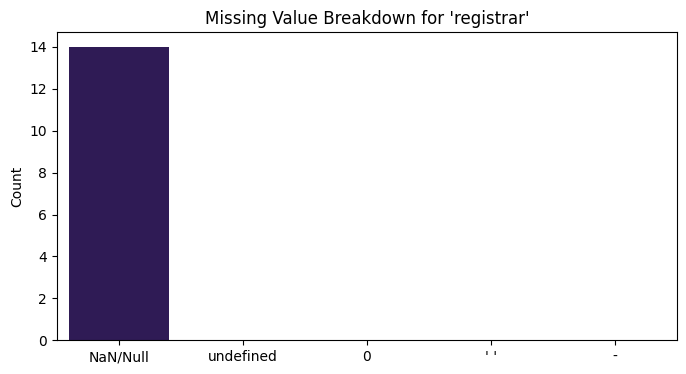

registration_date missing val:
'NaN/Null' = 21
'undefined' = 0
'0' = 0
'' '' = 0
'-' = 0


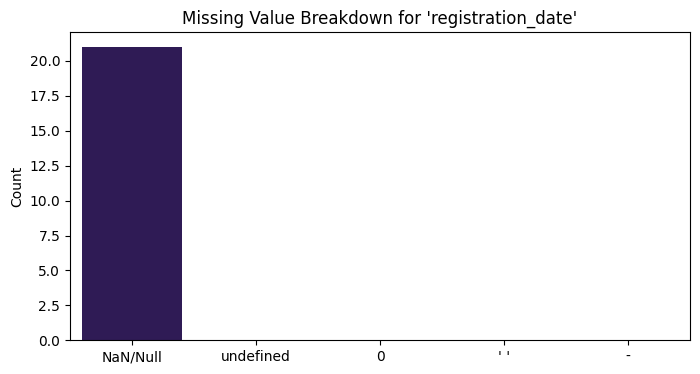

In [7]:
class MissingValueAnalyzer:
    def __init__(self, df, *placeholders):
        self.df = df
        # Check if the user passed a single list or individual arguments
        is_single_params = len(placeholders) == 1 and isinstance(placeholders[0], (list, tuple))
        if is_single_params:
            self.placeholders = list(placeholders[0])
        else:
            self.placeholders = list(placeholders)

        self.results = {}
        self._analyze()

    def _analyze(self):
        for col in self.df.columns:
            counts = {}
            for p in self.placeholders:
                is_param_nan = p is np.nan or p is pd.NA
                is_param_null = p is None

                if is_param_nan or is_param_null:
                    count = self.df[col].isna().sum()
                    label = "NaN/Null"
                else:
                    # Compare based on string representation to catch various formats
                    count = (self.df[col].astype(str) == str(p)).sum()
                    label = str(p) if str(p).strip() != "" else f"'{p}'"
                counts[label] = count
            self.results[col] = counts

    def __getattr__(self, name):
        if name in self.results:
            col_counts = self.results[name]
            print(f"{name} missing val:")
            for val, count in col_counts.items():
                print(f"'{val}' = {count}")

            # Visualization
            plt.figure(figsize=(8, 4))
            sns.barplot(x=list(col_counts.keys()), y=list(col_counts.values()), hue=list(col_counts.keys()), palette='magma', legend=False)
            plt.title(f"Missing Value Breakdown for '{name}'")
            plt.ylabel("Count")
            plt.show()
            return col_counts
        raise AttributeError(f"Column '{name}' not found.")

# Usage
POSIBLE_MISSING_VALS = [None, np.nan, "undefined", 0, " ", "-"]
getTheMVS = MissingValueAnalyzer(df, POSIBLE_MISSING_VALS)

# Accessing a specific column
brand_stats = getTheMVS.brand
brand_stats = getTheMVS.ip
brand_stats = getTheMVS.registrar
brand_stats = getTheMVS.registration_date

FEATURE ENGINEERING

In [8]:
import re
import math
import pandas as pd
import numpy as np
from pathlib import Path

Label Mapping

In [9]:
LABEL_MAP = {
    'online gambling' : 'online gambling',
    'Online Gambling'  : 'online gambling',
    'online gamblingg' : 'online gambling',
    'phishing'         : 'phishing',
    'phishingg'        : 'phishing',
    'malware'          : 'malware',
    'malwaree'         : 'malware',
    'spam'             : 'spam',
    'spamm'            : 'spam',
    'FakeShop'         : 'fakeshop',
    'brand'            : 'brand',
    'Brand'            : 'brand',
    'violence'         : 'violence',
    'PIIExposure'      : 'piiexposure',
    'other'            : 'other',
    'Other'            : 'other',
    'otherr'           : 'other',
}

In [10]:
df['label_temp'] = df['category'].map(LABEL_MAP)

group_key = (
    df['url'].astype(str) + '|' +
    df['registrar'].astype(str) + '|' +
    df['ip'].astype(str)
)

nunique_label_per_group = df.groupby(group_key)['label_temp'].transform('nunique')
is_true_noise = nunique_label_per_group > 1

n_before = len(df)
print(f"Baris terindikasi noise murni (url+registrar+ip identik, label beda): {is_true_noise.sum()}")
print("Distribusi label baris yang dibuang:")
print(df.loc[is_true_noise, 'label_temp'].value_counts())

df = df[~is_true_noise].reset_index(drop=True)
df = df.drop(columns=['label_temp'])

print(f"\nTotal baris: {n_before} → {len(df)} (dibuang: {n_before - len(df)})")
print("✓ df sudah bersih — seluruh cell setelah ini otomatis pakai data yang sudah dibersihkan")

Baris terindikasi noise murni (url+registrar+ip identik, label beda): 179
Distribusi label baris yang dibuang:
label_temp
online gambling    63
phishing           38
other              36
spam               21
malware            21
Name: count, dtype: int64

Total baris: 8400 → 8221 (dibuang: 179)
✓ df sudah bersih — seluruh cell setelah ini otomatis pakai data yang sudah dibersihkan


Keyword Signals

In [11]:
# Gambling: precision 93-100% di data asli — TIDAK diubah
GAMBLING_KEYWORDS = [
    'slot', 'togel', 'judi', 'gacor', 'bet', 'casino', 'poker',
    'sbobet', 'toto', 'games', 'maxwin', 'jackpot', 'bola',
    'pragmatic', 'scatter', 'deposit',
    'cartel', 'gamez', 'slotnesia', 'arena168', '4d', 'palem'
]
# Dihapus: 'pg soft' (0 match, string dengan spasi tidak pernah cocok),
#          'withdraw' (33% precision, cuma 3 match — noise > sinyal)

# Phishing: dihapus keyword presisi rendah (login 49%, auth 19%, password 50%)
PHISHING_KEYWORDS = [
    'signin', 'verify', 'confirm', 'account', 'secure',
    'update', 'validate', 'credential',
    'banking', 'fbck', '2fa', 'vacu', 'dna', 'free-fire',
    'mandm', 'paypal', 'whatsapp', 'hotwhatsapp'
]
# Dihapus: 'login' (49.5% precision, 218 match — separuh salah),
#          'auth' (19.1% precision, 47 match — mayoritas salah),
#          'password' (50%, sample terlalu kecil)

# Malware: dihapus keyword presisi sangat rendah
# '.php' adalah kasus terburuk: 616 match, presisi cuma 0.32%
MALWARE_KEYWORDS = [
    'xcc', 'exe', 'repository', 'repo'
]
# Dihapus: '.php' (0.32% precision, 616 match — noise terbesar),
#          'upload' (4.72%, 106 match), 'download' (0%, 18 match),
#          'file' (30.47%, 128 match), 'backup' (0%), 'cmd' (0%),
#          'eval' (0%), 'archive'/'.zip'/'.rar' (tidak pernah match di data)

# Brand impersonation — tidak diubah, tidak ada masalah presisi terdeteksi
BRAND_KEYWORDS = [
    'paypal', 'facebook', 'google', 'microsoft', 'apple',
    'amazon', 'netflix', 'whatsapp', 'telegram', 'dana',
    'shopee', 'tokopedia', 'bri', 'bca', 'mandiri', 'bni',
    'gojek', 'grab', 'ovo', 'gopay'
]

In [12]:
def shannon_entropy(s: str) -> float:
    """Entropy dari string — domain acak = entropy tinggi."""
    if not s:
        return 0.0
    freq = [s.count(c) / len(s) for c in set(s)]
    return -sum(p * math.log2(p) for p in freq if p > 0)


def count_keywords(text: str, keywords: list) -> int:
    text = text.lower()
    return sum(1 for kw in keywords if kw in text)


def extract_features(df: pd.DataFrame, is_train: bool = True) -> pd.DataFrame:
    feat = pd.DataFrame()
    url  = df['url'].fillna('').astype(str)
    domain = df['domain'].fillna('').astype(str)
    sld    = df['sld'].fillna('').astype(str)
    brand  = df['brand'].fillna('').astype(str)

    # URL Features
    feat['url_length']         = url.str.len()
    feat['url_digit_count']    = url.str.count(r'\d')
    feat['url_special_count']  = url.str.count(r'[%\-_=+&?#@!]')
    feat['url_slash_count']    = url.str.count('/')
    feat['url_dot_count']      = url.str.count(r'\.')
    feat['url_has_https']      = url.str.startswith('https').astype(int)
    feat['url_path_length']    = url.apply(
        lambda u: len(re.sub(r'^https?://[^/]+', '', u))
    )

    # Asterisk count = panjang bagian domain yang disembunyikan
    feat['domain_hidden_len']  = domain.str.count(r'\*')
    feat['domain_dot_count']   = domain.str.count(r'\.')
    feat['domain_entropy']     = domain.apply(
        lambda d: shannon_entropy(re.sub(r'\*+', '', d))
    )
    # Path entropy — sangat diskriminatif (violence/piiexposure tinggi
    # ~4.0, brand/fakeshop = 0, gambling 3.7, phishing 1.9)
    feat['path_entropy'] = url.apply(
        lambda u: shannon_entropy(re.sub(r'^https?://[^/]+', '', u))
    )

    # Keyword Signal Features
    feat['kw_gambling']   = url.apply(lambda u: count_keywords(u, GAMBLING_KEYWORDS))
    feat['kw_phishing']   = url.apply(lambda u: count_keywords(u, PHISHING_KEYWORDS))
    feat['kw_malware']    = url.apply(lambda u: count_keywords(u, MALWARE_KEYWORDS))
    feat['kw_brand']      = url.apply(lambda u: count_keywords(u, BRAND_KEYWORDS))
    feat['kw_brand_col']  = brand.apply(lambda b: count_keywords(b, BRAND_KEYWORDS))

    # SLD (Second-Level Domain) Features
    # go.id = gov (sering jadi target injeksi gambling)
    feat['sld_is_go']     = sld.str.contains('go.id').astype(int)
    feat['sld_is_ac']     = sld.str.contains('ac.id').astype(int)
    feat['sld_is_sch']    = sld.str.contains('sch.id').astype(int)
    feat['sld_is_biz']    = sld.str.contains('biz.id').astype(int)
    feat['sld_is_my']     = sld.str.contains('my.id').astype(int)
    feat['sld_is_co']     = sld.str.contains('co.id').astype(int)
    feat['sld_is_net']    = sld.str.contains('net.id').astype(int)
    feat['sld_is_ponpes'] = sld.str.contains('ponpes.id').astype(int)

    # Brand Column Features
    feat['brand_is_null']    = df['brand'].isna().astype(int)
    feat['brand_is_dash']    = (brand == '-').astype(int)
    feat['brand_has_value']  = (~df['brand'].isna() & (brand != '-')).astype(int)
    feat['brand_len']        = brand.apply(lambda b: len(b) if b != '-' else 0)

    # Temporal Features
    # Domain muda (baru didaftarkan) = suspicious
    reg_date  = pd.to_datetime(df['registration_date'], errors='coerce', format='mixed')
    disc_date = pd.to_datetime(df['discovered'], errors='coerce', format='mixed')

    feat['domain_age_days']  = (disc_date - reg_date).dt.days.fillna(-1)
    feat['domain_age_years'] = (feat['domain_age_days'] / 365).clip(lower=-1)
    feat['reg_year']         = reg_date.dt.year.fillna(0).astype(int)
    feat['disc_month']       = disc_date.dt.month.fillna(0).astype(int)
    feat['is_young_domain']  = (feat['domain_age_days'].between(0, 90)).astype(int)
    feat['is_very_new']      = (feat['domain_age_days'].between(0, 30)).astype(int)

    # Confidence Level
    feat['confidence_level'] = df['confidence_level'].fillna(100)
    feat['conf_is_high']     = (feat['confidence_level'] >= 250).astype(int)

    # IP Features
    feat['has_ip'] = df['ip'].notna().astype(int)

    # Registrar Features
    feat['has_registrar'] = df['registrar'].notna().astype(int)
    TOP_REGISTRARS = [
        'Kementerian Komunikasi dan Informatika',
        'PT Jagat Informasi Solusi (int)',
        'PT Digital Registra Indonesia',
        'PT JC Indonesia',
        'PT Registrasi Neva Angkasa',
        'PT Registrasi Nama Domain',
        'PT Web Media Technology Indonesia',
        'PT Jagoan Hosting Indonesia',
        'PT Cloud Hosting Indonesia',
        'PT Web Commerce Communications',
    ]
    registrar_col = df['registrar'].fillna('unknown')
    for reg in TOP_REGISTRARS:
        col_name = 'registrar_' + re.sub(r'[^a-z0-9]+', '_', reg.lower()).strip('_')
        feat[col_name] = (registrar_col == reg).astype(int)
    # Registrar di luar 10 besar (termasuk NaN) masuk kategori 'lainnya'
    feat['registrar_lainnya'] = (~registrar_col.isin(TOP_REGISTRARS)).astype(int)

    # Target (training only)
    if is_train:
        feat['label'] = df['category'].map(LABEL_MAP)

    return feat

# Main
if __name__ == '__main__':
    train_path   = Path(DRIVE_TRAINING_FILE_PATH)
    predict_path = Path(DRIVE_PREDICT_FILE_PATH)

    print('Loading data...')
    df_train   = pd.read_csv(train_path)
    df_predict = pd.read_csv(predict_path)

    print('Extracting features (training)...')
    feat_train = extract_features(df_train, is_train=True)

    print('Extracting features (predict)...')
    feat_predict = extract_features(df_predict, is_train=False)
    feat_predict.insert(0, 'id', df_predict['id'])

# Simpan
    DRIVE_FEATURES_TRAINING_FILE_PATH = '/content/drive/MyDrive/TeamLearningByDoing/data/processed/training_features.csv'
    DRIVE_FEATURES_PREDICT_FILE_PATH = '/content/drive/MyDrive/TeamLearningByDoing/data/processed/predict_features.csv'

    feat_train.to_csv(DRIVE_FEATURES_TRAINING_FILE_PATH, index=False)
    feat_predict.to_csv(DRIVE_FEATURES_PREDICT_FILE_PATH, index=False)

    print('\n✓ training_features.csv  :', feat_train.shape)
    print('✓ predict_features.csv   :', feat_predict.shape)
    print('\nFeatures:')
    for col in feat_train.columns:
        print(f'  {col}')

    print('\nLabel distribution (cleaned):')
    print(feat_train['label'].value_counts())

    print('\nSample null check:')
    print(feat_train.isnull().sum()[feat_train.isnull().sum() > 0])

Loading data...
Extracting features (training)...
Extracting features (predict)...

✓ training_features.csv  : (8400, 50)
✓ predict_features.csv   : (1500, 50)

Features:
  url_length
  url_digit_count
  url_special_count
  url_slash_count
  url_dot_count
  url_has_https
  url_path_length
  domain_hidden_len
  domain_dot_count
  domain_entropy
  path_entropy
  kw_gambling
  kw_phishing
  kw_malware
  kw_brand
  kw_brand_col
  sld_is_go
  sld_is_ac
  sld_is_sch
  sld_is_biz
  sld_is_my
  sld_is_co
  sld_is_net
  sld_is_ponpes
  brand_is_null
  brand_is_dash
  brand_has_value
  brand_len
  domain_age_days
  domain_age_years
  reg_year
  disc_month
  is_young_domain
  is_very_new
  confidence_level
  conf_is_high
  has_ip
  has_registrar
  registrar_kementerian_komunikasi_dan_informatika
  registrar_pt_jagat_informasi_solusi_int
  registrar_pt_digital_registra_indonesia
  registrar_pt_jc_indonesia
  registrar_pt_registrasi_neva_angkasa
  registrar_pt_registrasi_nama_domain
  registrar_pt_

In [13]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import re
import math # Added this line to import the math module
SEED = 42 # Added this line to define SEED for consistent random states

try:
    from wordcloud import WordCloud
except ImportError:
    !pip install wordcloud
    from wordcloud import WordCloud

print("Membuat Word Cloud untuk setiap kategori...")

categories = df_train['category'].dropna().unique()

n_cats = len(categories)
fig, axes = plt.subplots(nrows=math.ceil(n_cats / 2), ncols=2, figsize=(15, n_cats * 3))
axes = axes.flatten()

for i, cat in enumerate(categories):
    cat_urls = df_train[df_train['category'] == cat]['url'].astype(str).values
    text_corpus = " ".join(cat_urls)

    cleaned_text = re.sub(r'https?://|www\.', '', text_corpus)
    cleaned_text = re.sub(r'[^a-zA-Z\s]', ' ', cleaned_text) # Hanya ambil huruf

    if len(cleaned_text.strip()) > 0:
        wc = WordCloud(
            width=600,
            height=300,
            background_color='white',
            colormap='viridis',
            max_words=100,
            random_state=SEED
        ).generate(cleaned_text)

        axes[i].imshow(wc, interpolation='bilinear')
        axes[i].set_title(f"Kategori: {cat} (n={len(cat_urls)})", fontsize=12, fontweight='bold')
        axes[i].axis('off')
    else:
        axes[i].text(0.5, 0.5, f"Tidak ada teks untuk {cat}", horizontalalignment='center', verticalalignment='center')
        axes[i].axis('off')

# Hapus subplot kosong jika ada
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Output hidden; open in https://colab.research.google.com to view.

Handling Class Imbalance dengan SMOTE

In [14]:
!pip install imbalanced-learn -q
print("Pustaka berhasil di-install")

Pustaka berhasil di-install


In [15]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
import pandas as pd
import numpy as np

SEED = 42

feat_train_raw = pd.read_csv(DRIVE_FEATURES_TRAINING_FILE_PATH)
feature_cols = [c for c in feat_train_raw.columns if c != 'label']

binary_cols_idx = [
    i for i, c in enumerate(feature_cols)
    if c.startswith(('sld_is', 'registrar_', 'brand_is', 'brand_has'))
    or c in ['url_has_https', 'is_young_domain', 'is_very_new',
             'conf_is_high', 'has_ip', 'has_registrar']
]
kw_cols_idx = [i for i, c in enumerate(feature_cols) if c.startswith('kw_')]

def balance_data(X, y, seed=SEED):
    """
    RandomOverSampler + SMOTE — HANYA dipanggil pada X_train per-fold,
    TIDAK PERNAH pada X_validation. Ini yang mencegah data leakage.

    Kelas dgn 0 anggota di fold ini (bisa terjadi utk kelas super-rare)
    otomatis dilewati — tidak bisa di-oversample dari nol data.
    """
    y = np.asarray(y)
    counts = pd.Series(y).value_counts()

    ros_strategy   = {k: 100 for k, v in counts.items() if 0 < v < 6}
    smote_strategy = {k: 200 for k, v in counts.items() if 6 <= v < 200}

    X_res, y_res = X.copy(), y.copy()
    n_orig = len(X)

    if ros_strategy:
        ros = RandomOverSampler(sampling_strategy=ros_strategy, random_state=seed)
        X_res, y_res = ros.fit_resample(X_res, y_res)
        if len(X_res) > n_orig:
            noise = np.random.default_rng(seed).normal(0, 0.05, X_res[n_orig:].shape)
            X_res[n_orig:] = X_res[n_orig:] + noise

    if smote_strategy:
        cur = pd.Series(y_res).value_counts()
        smote_final = {k: v for k, v in smote_strategy.items() if cur.get(k, 0) < v}
        if smote_final:
            smote = SMOTE(sampling_strategy=smote_final, k_neighbors=5, random_state=seed)
            X_res, y_res = smote.fit_resample(X_res, y_res)

    X_res[:, binary_cols_idx] = np.clip(X_res[:, binary_cols_idx], 0, 1)
    X_res[:, kw_cols_idx]     = np.clip(X_res[:, kw_cols_idx], 0, None)
    return X_res, y_res

print("Fungsi balance_data() siap.")
print("PENTING: fungsi ini akan dipanggil per-fold di dalam CV nanti,")
print("BUKAN diterapkan ke seluruh dataset di sini — supaya tidak leakage.")
print()
print("Distribusi asli (SEBELUM balancing apapun):")
for k, v in sorted(pd.Series(feat_train_raw['label']).value_counts().items(), key=lambda x: -x[1]):
    print(f'  {k:22s}: {v}')

Fungsi balance_data() siap.
PENTING: fungsi ini akan dipanggil per-fold di dalam CV nanti,
BUKAN diterapkan ke seluruh dataset di sini — supaya tidak leakage.

Distribusi asli (SEBELUM balancing apapun):
  online gambling       : 5447
  phishing              : 2253
  other                 : 284
  spam                  : 185
  malware               : 179
  brand                 : 45
  fakeshop              : 5
  violence              : 1
  piiexposure           : 1


Load Matriks Features

In [16]:
import pandas as pd
import numpy as np
import warnings
from xgboost import XGBClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack, vstack
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score, classification_report
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings('ignore')
SEED = 42

feat_train = pd.read_csv(DRIVE_FEATURES_TRAINING_FILE_PATH)
feat_predict = pd.read_csv(DRIVE_FEATURES_PREDICT_FILE_PATH)

X_num = feat_train.drop(columns=['label']).values
y_train_text = feat_train['label'].values
X_pred_num = feat_predict.drop(columns=['id']).values
pred_ids = feat_predict['id'].values

le = LabelEncoder()
y_enc = le.fit_transform(y_train_text)

print(f"Bentuk data latih numerik: {X_num.shape}")
print(f"Bentuk data prediksi numerik: {X_pred_num.shape}")
print("Kelas yang terdeteksi:", list(le.classes_))

Bentuk data latih numerik: (8400, 49)
Bentuk data prediksi numerik: (1500, 49)
Kelas yang terdeteksi: ['brand', 'fakeshop', 'malware', 'online gambling', 'other', 'phishing', 'piiexposure', 'spam', 'violence']


Load Feature Matrix (Numerik Only)

In [17]:
X_hybrid      = X_num
X_pred_hybrid = X_pred_num

print(f"Bentuk Matriks Latih   : {X_hybrid.shape}")
print(f"Bentuk Matriks Prediksi: {X_pred_hybrid.shape}")

Bentuk Matriks Latih   : (8400, 49)
Bentuk Matriks Prediksi: (1500, 49)


In [18]:
from sklearn.preprocessing import LabelEncoder

N_SPLITS = 5

global_counts = pd.Series(y_train_text).value_counts()
cv_excluded = set(global_counts[global_counts < N_SPLITS].index)
print(f"Kelas dikeluarkan dari CV (n < {N_SPLITS}): {cv_excluded}")
print("(Kelas ini tetap dipakai penuh untuk model final di Cell 37)")

cv_mask = ~pd.Series(y_train_text).isin(cv_excluded).values
X_cv = X_hybrid[cv_mask]
y_cv_text = y_train_text[cv_mask]

le_cv = LabelEncoder()
y_cv_enc = le_cv.fit_transform(y_cv_text)

print(f"\nData untuk CV: {X_cv.shape} | kelas: {list(le_cv.classes_)}")

Kelas dikeluarkan dari CV (n < 5): {'piiexposure', 'violence'}
(Kelas ini tetap dipakai penuh untuk model final di Cell 37)

Data untuk CV: (8398, 49) | kelas: ['brand', 'fakeshop', 'malware', 'online gambling', 'other', 'phishing', 'spam']


### K-Fold Cross Validation

In [19]:
!pip install optuna
print("Pustaka berhasil di-install")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 12.1 MB/s eta 0:00:00
Pustaka berhasil di-install


In [20]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import f1_score, classification_report
from sklearn.utils.class_weight import compute_sample_weight

SEED = 42
CV       = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # validasi akhir
CV_TUNE  = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)  # searching (cepat)

In [21]:
# Optuna Tuning
def xgb_objective(trial):
    params = dict(
        n_estimators     = trial.suggest_int('n_estimators', 200, 800),
        max_depth        = trial.suggest_int('max_depth', 3, 8),
        learning_rate    = trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        subsample        = trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree = trial.suggest_float('colsample_bytree', 0.5, 1.0),
        min_child_weight = trial.suggest_int('min_child_weight', 1, 10),
        gamma            = trial.suggest_float('gamma', 0, 0.5),
        reg_alpha        = trial.suggest_float('reg_alpha', 0, 1.0),
        reg_lambda       = trial.suggest_float('reg_lambda', 0.5, 2.0),
        eval_metric      = 'mlogloss',
        tree_method      = 'hist',
        random_state     = SEED,
        n_jobs           = -1,
    )

    fold_scores = []
    for train_idx, val_idx in CV_TUNE.split(X_cv, y_cv_enc):
        X_tr, X_vl = X_cv[train_idx], X_cv[val_idx]
        y_tr, y_vl = y_cv_enc[train_idx], y_cv_enc[val_idx]

        # SMOTE HANYA di training fold — validation fold tetap murni/asli
        X_tr_bal, y_tr_bal = balance_data(X_tr, y_tr)

        model = XGBClassifier(**params)
        weights_tr = compute_sample_weight(class_weight='balanced', y=y_tr_bal)
        model.fit(X_tr_bal, y_tr_bal, sample_weight=weights_tr)

        y_pred_fold = model.predict(X_vl)
        fold_scores.append(f1_score(y_vl, y_pred_fold, average='macro', zero_division=0))

    return np.mean(fold_scores)

print("Tuning XGBoost (60 trials, 3-fold, SMOTE per-fold — tanpa leakage)...")
study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study.optimize(xgb_objective, n_trials=60, show_progress_bar=True)

# xgb_params_cv: dipakai untuk validasi 5-fold di bawah (TANPA num_class)
xgb_params_cv = dict(study.best_params)
xgb_params_cv.update({
    'eval_metric' : 'mlogloss',
    'tree_method' : 'hist',
    'random_state': SEED,
    'n_jobs'      : -1,
})

# xgb_params: dipakai KHUSUS untuk model final di Cell 37
# (num_class aman di sini karena tidak ada train/val split lagi)
xgb_params = dict(study.best_params)
xgb_params.update({
    'objective'   : 'multi:softmax',
    'num_class'   : len(le.classes_),
    'eval_metric' : 'mlogloss',
    'tree_method' : 'hist',
    'random_state': SEED,
    'n_jobs'      : -1,
})

print(f"\n✓ Best 3-fold CV Macro-F1 (search): {study.best_value:.4f}")
print(f"Best params: {study.best_params}")

# ── Validasi akhir 5-Fold — SMOTE per-fold, tanpa leakage ──
print("\nValidasi 5-Fold (resmi) dengan params terbaik...")
y_oof_pred_enc = np.zeros(len(y_cv_enc), dtype=int)

for fold, (train_idx, val_idx) in enumerate(CV.split(X_cv, y_cv_enc), 1):
    print(f"  Fold {fold}...")
    X_tr, X_vl = X_cv[train_idx], X_cv[val_idx]
    y_tr, y_vl = y_cv_enc[train_idx], y_cv_enc[val_idx]

    X_tr_bal, y_tr_bal = balance_data(X_tr, y_tr)
    weights_tr = compute_sample_weight(class_weight='balanced', y=y_tr_bal)

    model_cv = XGBClassifier(**xgb_params_cv)
    model_cv.fit(X_tr_bal, y_tr_bal, sample_weight=weights_tr)
    y_oof_pred_enc[val_idx] = model_cv.predict(X_vl)

y_oof_text  = le_cv.inverse_transform(y_oof_pred_enc)
y_true_text = le_cv.inverse_transform(y_cv_enc)

macro_f1_ml = f1_score(y_true_text, y_oof_text, average='macro', zero_division=0)
print(f"\n✓ K-Fold finished!")
print(f"Macro-F1 Score (XGBoost Tuned, 5-fold resmi, TANPA leakage): {macro_f1_ml:.5f}")
print("(Catatan: dihitung dari 7 kelas yang cukup datanya untuk divalidasi;")
print(" violence & piiexposure dikeluarkan dari CV — lihat cell sebelumnya)")

print("\n--- CLASSIFICATION REPORT (OOF, jujur) ---")
print(classification_report(y_true_text, y_oof_text, zero_division=0))

Tuning XGBoost (60 trials, 3-fold, SMOTE per-fold — tanpa leakage)...


  0%|          | 0/60 [00:00<?, ?it/s]


✓ Best 3-fold CV Macro-F1 (search): 0.9014
Best params: {'n_estimators': 732, 'max_depth': 3, 'learning_rate': 0.0545550255139116, 'subsample': 0.9935120403031686, 'colsample_bytree': 0.6631651002664432, 'min_child_weight': 2, 'gamma': 0.29285424294461004, 'reg_alpha': 0.24571590604722318, 'reg_lambda': 1.1324822824221792}

Validasi 5-Fold (resmi) dengan params terbaik...
  Fold 1...
  Fold 2...
  Fold 3...
  Fold 4...
  Fold 5...

✓ K-Fold finished!
Macro-F1 Score (XGBoost Tuned, 5-fold resmi, TANPA leakage): 0.91426
(Catatan: dihitung dari 7 kelas yang cukup datanya untuk divalidasi;
 violence & piiexposure dikeluarkan dari CV — lihat cell sebelumnya)

--- CLASSIFICATION REPORT (OOF, jujur) ---
                 precision    recall  f1-score   support

          brand       0.98      1.00      0.99        45
       fakeshop       1.00      1.00      1.00         5
        malware       0.69      0.81      0.74       179
online gambling       0.99      0.99      0.99      5447
       

LightGBM Tuning & Ensemble Evaluation

In [22]:
!pip install lightgbm -q

In [23]:
import lightgbm as lgb

CV_TUNE_LGBM = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

def lgbm_objective(trial):
    params = dict(
        n_estimators      = trial.suggest_int('n_estimators', 200, 800),
        max_depth         = trial.suggest_int('max_depth', 3, 8),
        learning_rate     = trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        num_leaves        = trial.suggest_int('num_leaves', 20, 100),
        subsample         = trial.suggest_float('subsample', 0.6, 1.0),
        colsample_bytree  = trial.suggest_float('colsample_bytree', 0.5, 1.0),
        min_child_samples = trial.suggest_int('min_child_samples', 5, 50),
        reg_alpha         = trial.suggest_float('reg_alpha', 0, 1.0),
        reg_lambda        = trial.suggest_float('reg_lambda', 0.5, 2.0),
        class_weight      = 'balanced',
        random_state      = SEED,
        n_jobs            = -1,
        verbose           = -1,
    )

    fold_scores = []
    for train_idx, val_idx in CV_TUNE_LGBM.split(X_cv, y_cv_enc):
        X_tr, X_vl = X_cv[train_idx], X_cv[val_idx]
        y_tr_enc, y_vl_enc = y_cv_enc[train_idx], y_cv_enc[val_idx]

        X_tr_bal, y_tr_bal_enc = balance_data(X_tr, y_tr_enc)
        y_tr_bal_text = le_cv.inverse_transform(y_tr_bal_enc)

        model = lgb.LGBMClassifier(**params)
        model.fit(X_tr_bal, y_tr_bal_text)

        y_pred_fold_text = model.predict(X_vl)
        y_pred_fold_enc  = le_cv.transform(y_pred_fold_text)
        fold_scores.append(f1_score(y_vl_enc, y_pred_fold_enc, average='macro', zero_division=0))

    return np.mean(fold_scores)

print("Tuning LightGBM (40 trials, 3-fold, SMOTE per-fold)...")
study_lgbm = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study_lgbm.optimize(lgbm_objective, n_trials=40, show_progress_bar=True)

lgbm_params = study_lgbm.best_params
lgbm_params.update({'class_weight': 'balanced', 'random_state': SEED, 'n_jobs': -1, 'verbose': -1})

print(f"\n✓ Best LightGBM 3-fold CV: {study_lgbm.best_value:.4f}")
print(f"Best params: {study_lgbm.best_params}")

# ── Ensemble: soft voting XGB + LightGBM (5-fold resmi, SMOTE per-fold) ──
print("\nMenghitung Ensemble (XGB + LightGBM) — 5-fold resmi, tanpa leakage...")

classes_sorted = le_cv.classes_
ensemble_oof_proba = np.zeros((len(y_cv_enc), len(classes_sorted)))

for fold, (train_idx, val_idx) in enumerate(CV.split(X_cv, y_cv_enc), 1):
    print(f"  Fold {fold}...")
    X_tr, X_vl = X_cv[train_idx], X_cv[val_idx]
    y_tr_enc, y_vl_enc = y_cv_enc[train_idx], y_cv_enc[val_idx]

    X_tr_bal, y_tr_bal_enc = balance_data(X_tr, y_tr_enc)
    y_tr_bal_text = le_cv.inverse_transform(y_tr_bal_enc)
    weights_tr = compute_sample_weight(class_weight='balanced', y=y_tr_bal_enc)

    # XGBoost — pakai xgb_params_cv (TANPA num_class, aman utk per-fold)
    m_xgb = XGBClassifier(**xgb_params_cv)
    m_xgb.fit(X_tr_bal, y_tr_bal_enc, sample_weight=weights_tr)
    p_xgb_raw = m_xgb.predict_proba(X_vl)
    p_xgb = np.zeros((len(val_idx), len(classes_sorted)))
    for ci, cls_enc in enumerate(m_xgb.classes_):
        p_xgb[:, cls_enc] = p_xgb_raw[:, ci]

    # LightGBM
    m_lgbm = lgb.LGBMClassifier(**lgbm_params)
    m_lgbm.fit(X_tr_bal, y_tr_bal_text)
    p_lgbm_raw = m_lgbm.predict_proba(X_vl)
    p_lgbm = np.zeros_like(p_xgb)
    for ci, cls in enumerate(classes_sorted):
        if cls in m_lgbm.classes_:
            p_lgbm[:, ci] = p_lgbm_raw[:, list(m_lgbm.classes_).index(cls)]

    ensemble_oof_proba[val_idx] = (p_xgb + p_lgbm) / 2

y_ensemble_pred_enc = np.argmax(ensemble_oof_proba, axis=1)
y_ensemble_text = classes_sorted[y_ensemble_pred_enc]

macro_f1_ensemble = f1_score(y_true_text, y_ensemble_text, average='macro', zero_division=0)

print(f"\n{'='*50}")
print(f"XGBoost sendiri  : {macro_f1_ml:.5f}")
print(f"Ensemble XGB+LGBM: {macro_f1_ensemble:.5f}")
print(f"{'='*50}")

USE_ENSEMBLE = macro_f1_ensemble > macro_f1_ml
if USE_ENSEMBLE:
    print(f"\n✓ Ensemble LEBIH BAIK (+{macro_f1_ensemble - macro_f1_ml:.5f}) — akan dipakai untuk submission")
else:
    print(f"\n✓ XGBoost sendiri LEBIH BAIK — ensemble TIDAK dipakai untuk submission")

Tuning LightGBM (40 trials, 3-fold, SMOTE per-fold)...


  0%|          | 0/40 [00:00<?, ?it/s]


✓ Best LightGBM 3-fold CV: 0.8282
Best params: {'n_estimators': 203, 'max_depth': 7, 'learning_rate': 0.0779168263591414, 'num_leaves': 79, 'subsample': 0.9416279834816846, 'colsample_bytree': 0.5460686498218478, 'min_child_samples': 11, 'reg_alpha': 0.053133385301713444, 'reg_lambda': 0.8468193945641537}

Menghitung Ensemble (XGB + LightGBM) — 5-fold resmi, tanpa leakage...
  Fold 1...
  Fold 2...
  Fold 3...
  Fold 4...
  Fold 5...

XGBoost sendiri  : 0.91426
Ensemble XGB+LGBM: 0.90267

✓ XGBoost sendiri LEBIH BAIK — ensemble TIDAK dipakai untuk submission


### Heuristic Post-Processing

In [24]:
def apply_post_processing(urls, ml_predictions):
    final_preds = list(ml_predictions).copy()

    GAMBLING_KW = [
        'slot', 'togel', 'judi', 'gacor', 'sbobet', 'casino',
        'poker', 'maxwin', 'jackpot', 'slotmaxwin', 'cobaslot',
        'scatter', '4d', 'toto4d', 'slotgacor', 'judionline'
    ]
    PHISHING_KW = [
        'verify-account', 'confirm-account', 'secure-login',
        'vacu', 'vhsfhqpdhdsih', 'codaapaymn', 'fbck',
        'hotwhatsapp', 'free-fire-diamond', 'mandm-direct'
    ]
    MALWARE_KW = [
        'repository', 'statics/gudangsoal', 'xcc-shell',
        'payload', 'base64decode', 'eval(base64'
    ]

    for i, url in enumerate(urls):
        url_lower = str(url).lower()

        # Setiap kondisi dicek INDEPENDEN — bukan elif berantai.
        # Supaya keyword phishing/malware tetap bisa mengoreksi
        # walaupun prediksi awal bukan gambling.

        if final_preds[i] != 'online gambling' and any(kw in url_lower for kw in GAMBLING_KW):
            final_preds[i] = 'online gambling'
            continue  # sekali URL match gambling, tidak perlu dicek lagi

        if final_preds[i] != 'phishing' and any(kw in url_lower for kw in PHISHING_KW):
            final_preds[i] = 'phishing'
            continue

        if final_preds[i] != 'malware' and any(kw in url_lower for kw in MALWARE_KW):
            final_preds[i] = 'malware'
            continue

        # fakeshop, violence, piiexposure: TIDAK di-override via heuristic
        # karena keyword yang tersedia terlalu generik dan merusak prediksi ML

    return final_preds

y_oof_post = apply_post_processing(df_train['url'].values[cv_mask], y_oof_text)

macro_f1_post = f1_score(y_true_text, y_oof_post, average='macro', zero_division=0)

print(f"Macro-F1 Score              : {macro_f1_ml:.5f}")
print(f"MACRO-F1 ESTIMATE SCORE (POST) : {macro_f1_post:.5f}\n")

print("--- CLASSIFICATION REPORT (AFTER POST-PROCESSING) ---")
print(classification_report(y_true_text, y_oof_post, zero_division=0))

Macro-F1 Score              : 0.91426
MACRO-F1 ESTIMATE SCORE (POST) : 0.92417

--- CLASSIFICATION REPORT (AFTER POST-PROCESSING) ---
                 precision    recall  f1-score   support

          brand       0.98      1.00      0.99        45
       fakeshop       1.00      1.00      1.00         5
        malware       0.79      0.82      0.80       179
online gambling       0.98      0.99      0.99      5447
          other       0.96      0.95      0.95       284
       phishing       0.99      0.94      0.96      2253
           spam       0.73      0.83      0.78       185

       accuracy                           0.97      8398
      macro avg       0.92      0.93      0.92      8398
   weighted avg       0.97      0.97      0.97      8398



In [25]:
import pandas as pd
import numpy as np
import unicodedata

In [26]:
VALID_CATEGORIES = {
    "online gambling", "phishing", "other", "spam", "malware",
    "brand", "fakeshop", "violence", "piiexposure",
}

def normalize_category(value):
    value = unicodedata.normalize("NFKC", str(value)).casefold()
    return " ".join(value.split())

# Balancing pada SELURUH data training (9 kelas) untuk model final
X_final_bal, y_final_bal_enc = balance_data(X_hybrid, y_enc)
sample_weights = compute_sample_weight(class_weight='balanced', y=y_final_bal_enc)

if USE_ENSEMBLE:
    print("Training final ENSEMBLE (XGB + LightGBM) pada seluruh data...")
    final_xgb = XGBClassifier(**xgb_params)  # num_class=9 aman di sini
    final_xgb.fit(X_final_bal, y_final_bal_enc, sample_weight=sample_weights)

    y_final_bal_text = le.inverse_transform(y_final_bal_enc)
    final_lgbm = lgb.LGBMClassifier(**lgbm_params)
    final_lgbm.fit(X_final_bal, y_final_bal_text)

    p_xgb_test = final_xgb.predict_proba(X_pred_hybrid)
    p_lgbm_raw_test = final_lgbm.predict_proba(X_pred_hybrid)

    classes_final = le.classes_
    p_lgbm_test = np.zeros_like(p_xgb_test)
    for ci, cls in enumerate(classes_final):
        if cls in final_lgbm.classes_:
            p_lgbm_test[:, ci] = p_lgbm_raw_test[:, list(final_lgbm.classes_).index(cls)]

    p_ensemble_test = (p_xgb_test + p_lgbm_test) / 2
    y_pred_text = classes_final[np.argmax(p_ensemble_test, axis=1)]

else:
    print("Training final XGBoost (sendiri) pada seluruh data...")
    final_model = XGBClassifier(**xgb_params)  # num_class=9 aman di sini
    final_model.fit(X_final_bal, y_final_bal_enc, sample_weight=sample_weights)
    y_pred_enc = final_model.predict(X_pred_hybrid)
    y_pred_text = le.inverse_transform(y_pred_enc)

print("✓ Training selesai.")

# ── Post-processing ───────────────────────────────────
predict_urls = df_predict['url'].astype(str).values
y_pred_post  = apply_post_processing(predict_urls, y_pred_text)

# ── Normalisasi ke format valid panitia ──────────────
y_pred_valid = np.array([normalize_category(p) for p in y_pred_post])

# ── Validasi ──────────────────────────────────────────
invalid_mask = ~np.isin(y_pred_valid, list(VALID_CATEGORIES))
if invalid_mask.sum() > 0:
    print(f"[WARNING] {invalid_mask.sum()} label tidak valid → di-set ke 'other'")
    print("Label tidak valid:", np.unique(y_pred_valid[invalid_mask]))
    y_pred_valid[invalid_mask] = 'other'
else:
    print("✓ Semua label valid.")

Training final XGBoost (sendiri) pada seluruh data...
✓ Training selesai.
✓ Semua label valid.


In [28]:
# ── Simpan submission ─────────────────────────────────
df_submission = pd.DataFrame({'id': pred_ids, 'category': y_pred_valid})
df_submission.to_csv('/content/drive/MyDrive/TeamLearningByDoing/submissions/TeamLearningByDoing-003nosmote.csv', index=False)

print(f"\n✓ Submission disimpan: /content/drive/MyDrive/TeamLearningByDoing/submissions/TeamLearningByDoing-003nosmote.csv")
print(f"  Total baris : {len(df_submission)}")
print(f"  Duplikat ID : {df_submission['id'].duplicated().sum()}")
print(f"  Null        : {df_submission.isnull().sum().sum()}")
print("\nDistribusi prediksi:")
print(df_submission['category'].value_counts().to_string())


✓ Submission disimpan: /content/drive/MyDrive/TeamLearningByDoing/submissions/TeamLearningByDoing-003nosmote.csv
  Total baris : 1500
  Duplikat ID : 0
  Null        : 0

Distribusi prediksi:
category
online gambling    986
phishing           384
other               49
spam                41
malware             31
brand                7
fakeshop             2
